## Graphical abstract v3: 4 × 4 in (Cell Press format), UMAP and dendrogram versions

Both versions are one square panel, 1200 × 1200 px at 300 dpi (4 × 4 in), Arial 11–13 pt (Cell Press asks for 12–16 pt;
the cluster names are 11 pt to fit). Shared header: title + key images framed in the experience-level colors.

- **`umap`**: UMAP of the clustered cells (cluster 1 and the far outliers removed, as in the original abstract), colored by each
  cluster's **preferred experience level** (gray = no preference), marker = cell type; per-cell-type pies (one wedge per
  cluster, same order and fractions as `graphical_abstract_v2`, fill = preferred experience); one example cluster trace per pie.
- **`dendrogram`**: the Figure 5 dendrogram; cluster names colored by **preferred feature**, leaf dots by preferred experience;
  bubbles = % of each cell type's cells per cluster (area ∝ %).

Data-loading and cluster-preference cells are copied unchanged from `graphical_abstract_v2.ipynb`.
Saves `graphical_abstract_v3_umap.{tif,png,pdf}` and `graphical_abstract_v3_dendrogram.{tif,png,pdf}`. Layout knobs are at the top of the last cell.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context('notebook', font_scale=1.5, rc={'lines.markeredgewidth': 1})

# Visual behavior analysis package functions
import visual_behavior.visualization.utils as utils
import visual_behavior.data_access.loading as loading

# Clustering modules
from visual_behavior.dimensionality_reduction.clustering import plotting
from visual_behavior.dimensionality_reduction.clustering import processing

%load_ext autoreload
%autoreload 2
%matplotlib inline

ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.py", line 632, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.py", line 687, in __get__
    return t.cast(G, self.get(obj, cls))  # the G should encode the Optional
  File "/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/traitlets/traitlets.p

In [2]:
save_dir = os.path.join(loading.get_figures_save_dir(), 'platform_paper_figures', 'graphical_abstract_v3')
os.makedirs(save_dir, exist_ok=True)

## Data loading (from graphical_abstract_v2)

In [3]:
# Curated metadata tables
metadata_tables_dir = loading.get_metadata_tables_dir()
platform_experiments = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_experiments_table.csv'), index_col=0)
platform_cells_table = pd.read_csv(os.path.join(metadata_tables_dir, 'platform_paper_ophys_cells_table.csv'), index_col=0)

cell_types = utils.get_cell_types()
experience_levels = utils.get_experience_levels()

In [4]:
glm_results_dir = loading.get_glm_results_dir()
data_dir = loading.get_clustering_results_dir()

# Clustering results (same files as figure_5_main)
feature_matrix = pd.read_hdf(os.path.join(data_dir, 'clustering_feature_matrix.h5'), key='df')
feature_matrix = feature_matrix.rename(columns={'all-images': 'images', 'behavioral': 'behavior'})

n_clusters = 14
cluster_meta = pd.read_hdf(os.path.join(data_dir, f'cluster_metadata_{n_clusters}_clusters.h5'), key='df')

# Coding scores - normalized for clustering
results_pivoted = pd.read_hdf(os.path.join(glm_results_dir, 'across_session_normalized_platform_results_pivoted.h5'), key='df')

### Cluster preferences, dendrogram order, pie fractions (from graphical_abstract_v2)

In [5]:
# ---- per-cluster preferred feature + preferred experience, dendrogram order, pie fractions ----
# Same definitions as the Figure 5 main dendrogram (panel C of figure_5_main composite), copied so
# this notebook is self-contained. Uses only stable vars: cluster_meta, feature_matrix, results_pivoted.
#   preferred feature    = dominant feature from processing.get_coding_score_metrics_for_clusters
#   preferred experience = Familiar vs mean(Novel, Novel +) on the dominant feature:
#       novelty index = (mean(N, N+) - F) / (mean(N, N+) + F)
#       >= +EXP_SEL_MIN -> larger of Novel / Novel + ; <= -EXP_SEL_MIN -> Familiar ; else no preference
#       peak coding < EXP_SCORE_MIN -> no preference and gray feature (non-coding)
from scipy.cluster.hierarchy import linkage, dendrogram

EXP_SEL_MIN = 0.15
EXP_SCORE_MIN = 0.1

features = processing.get_features_for_clustering()           # ['all-images', 'omissions', 'task', 'behavioral']
feature_cols = plotting.get_feature_colors_with_gray()         # [gray] + one color per feature
exp_levels, exp_cols = utils.get_experience_levels(), utils.get_experience_level_colors()
FAM, NOV, NOVP = exp_levels

cm = processing.get_coding_score_metrics_for_clusters(cluster_meta, results_pivoted)
rp = (results_pivoted if 'cluster_id' in results_pivoted.columns
      else results_pivoted.merge(cluster_meta[['cluster_id']], on='cell_specimen_id'))
lvl_means = rp.groupby(['cluster_id', 'experience_level'])[features].mean()

rows = []
for c in cm.index:
    feat = cm.loc[c, 'dominant_feature']
    v = lvl_means.loc[c][feat]
    fam, nov = v[FAM], (v[NOV] + v[NOVP]) / 2
    idx = (nov - fam) / (nov + fam) if (nov + fam) > 0 else 0.0
    pref = (NOV if v[NOV] >= v[NOVP] else NOVP) if idx >= EXP_SEL_MIN else (FAM if idx <= -EXP_SEL_MIN else None)
    noncoding = max(fam, v[NOV], v[NOVP]) < EXP_SCORE_MIN
    if noncoding:
        pref = None
    rows.append(dict(cluster_id=c, dominant_feature=feat, Familiar=fam, Novel=v[NOV], **{'Novel +': v[NOVP]},
                     novelty_index=idx, preferred_experience=pref,
                     feature_color=feature_cols[0] if noncoding else feature_cols[1 + features.index(feat)],
                     exp_color=exp_cols[exp_levels.index(pref)] if pref is not None else None))
cluster_info = pd.DataFrame(rows).set_index('cluster_id').sort_index()

# dendrogram of cluster-mean coding scores (Euclidean, average linkage) -- identical to Fig 5
cent = feature_matrix.loc[cluster_meta.index].groupby(cluster_meta.cluster_id.values).mean()
dendro_Z = linkage(cent.values, method='average', metric='euclidean')
dendro_labels = list(cent.index)
# leaf order TOP -> BOTTOM as drawn with orientation='left' (scipy lists leaves bottom -> top)
leaf_order = list(dendrogram(dendro_Z, labels=dendro_labels, no_plot=True)['ivl'])[::-1]
cluster_info['dendro_rank'] = [leaf_order.index(c) for c in cluster_info.index]

# fraction of each cell type's cells in each cluster (full population, incl. cluster 1)
cell_types = utils.get_cell_types()
pie_fracs = (cluster_meta.groupby(['cell_type', 'cluster_id']).size()
             .unstack(fill_value=0).reindex(index=cell_types, columns=leaf_order, fill_value=0))
pie_fracs = pie_fracs.div(pie_fracs.sum(axis=1), axis=0)

print('leaf order (top -> bottom):', leaf_order)
print(cluster_info[['dominant_feature', FAM, NOV, NOVP, 'novelty_index', 'preferred_experience']].round(2).to_string())
print('\n% of cells per cluster, per cell type (columns in dendrogram order):')
print((100 * pie_fracs).round(1).to_string())

leaf order (top -> bottom): [9, 8, 11, 10, 1, 12, 3, 2, 5, 7, 6, 4]
           dominant_feature  Familiar  Novel  Novel +  novelty_index preferred_experience
cluster_id                                                                               
1                all-images      0.01   0.00     0.00          -0.40                 None
2                all-images      0.03   0.89     0.09           0.90                Novel
3                all-images      0.08   0.79     0.77           0.81                Novel
4                all-images      0.91   0.06     0.06          -0.87             Familiar
5                all-images      0.03   0.10     0.90           0.90              Novel +
6                all-images      0.72   0.30     0.74          -0.16             Familiar
7                all-images      0.73   0.74     0.25          -0.19             Familiar
8                 omissions      0.64   0.11     0.16          -0.65             Familiar
9                 omissions     

In [6]:
# pie wedge order, as graphical_abstract_v2 with PIE_ORDER = 'experience' (by preferred experience, then feature, then dendrogram)
exp_rank = {lvl: i for i, lvl in enumerate(exp_levels)}
feat_rank = {f: i for i, f in enumerate(features)}
pie_order = sorted(cluster_info.index, key=lambda c: (
    exp_rank.get(cluster_info.loc[c, 'preferred_experience'], len(exp_levels)),
    len(features) if cluster_info.loc[c, 'feature_color'] == feature_cols[0] else feat_rank[cluster_info.loc[c, 'dominant_feature']],
    cluster_info.loc[c, 'dendro_rank']))
print('pie order:', pie_order)

# UMAP points (as the original abstract): saved UMAP, cluster 1 and far outliers (x >= 16) removed
umap_df = pd.read_hdf(os.path.join(data_dir, 'umap_results_df.h5'), key='df')
scatter_umap = umap_df.loc[cluster_meta[cluster_meta.cluster_id != 1].index, ['x', 'y']].copy()
scatter_umap = scatter_umap[scatter_umap.x < 16]
scatter_umap = scatter_umap.join(cluster_meta[['cluster_id', 'cell_type']])
print(len(scatter_umap), 'cells in the UMAP')

pie order: [7, 6, 4, 8, 10, 3, 2, 11, 5, 9, 12, 1]
2941 cells in the UMAP


### Example-trace data (from graphical_abstract_v2; slow, cached)

In [7]:
# ---- data for cluster average-response traces (loaded once; slow) ----
if ('change_mdf' not in globals()) or ('omission_mdf' not in globals()):
    _dt, _interp, _osr, _incl = 'events', True, 30, 'platform_experiment_table'
    _msdf = loading.get_multi_session_df_for_conditions(
        _dt, event_type='all', conditions=['cell_specimen_id', 'is_change'],
        inclusion_criteria=_incl, interpolate=_interp, output_sampling_rate=_osr, epoch_duration_mins=None)
    _clu = cluster_meta.reset_index()[['cell_specimen_id', 'cluster_id']]
    change_mdf = _msdf[_msdf.is_change == True].merge(_clu, on='cell_specimen_id')
    image_mdf  = _msdf[_msdf.is_change == False].merge(_clu, on='cell_specimen_id')
    omission_mdf = loading.get_multi_session_df_for_conditions(
        _dt, event_type='all', conditions=['cell_specimen_id', 'omitted'],
        inclusion_criteria=_incl, interpolate=_interp, output_sampling_rate=_osr, epoch_duration_mins=None)
    omission_mdf = omission_mdf[omission_mdf.omitted == True].merge(_clu, on='cell_specimen_id')
    _thr = 99.9
    image_mdf, _    = processing.remove_outliers(image_mdf, _thr)
    change_mdf, _   = processing.remove_outliers(change_mdf, _thr)
    omission_mdf, _ = processing.remove_outliers(omission_mdf, _thr)
    # peak-amplitude outlier filtering (Method C), as the old abstract applied before plotting traces
    change_mdf = utils.drop_peak_outliers(change_mdf, data_type='events', scope='trace')
    omission_mdf = utils.drop_peak_outliers(omission_mdf, data_type='events', scope='trace')
    print('loaded change_mdf', change_mdf.shape, '| omission_mdf', omission_mdf.shape)
else:
    print('change_mdf / omission_mdf already loaded; skipping reload')

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_is_change_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_is_change_platform_experiment_table.feather
there are 1881 experiments in the full multi_session_df
there are 400 experiments in the multi_session_df after limiting to platform experiments
there are 400 experiments after filtering for inclusion criteria -  platform_experiment_table


/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

1936
loading files from /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs
mean_response_df_events_all_omitted_platform_experiment_table.pkl
loading multi_session_df from saved feather file at /Users/marinag/Library/CloudStorage/Dropbox/JupyterNotebooks/FinalDataAssetsforCodeOcean/visual_behavior_ophys_multi_session_dfs/mean_response_df_events_all_omitted_platform_experiment_table.feather
there are 1879 experiments in the full multi_session_df
there are 401 experiments in the multi_session_df after limiting to platform experiments
there are 401 experiments after filtering for inclusion criteria -  platform_experiment_table
loaded change_mdf (11598, 65) | omission_mdf (11609, 65)


### Key images (from graphical_abstract_v2; cached)

In [8]:
# ---- data for the top-band stimulus image grids (familiar + novel), cached ----
if ('familiar_templates' not in globals()) or ('novel_templates' not in globals()):
    def _rep_stim_templates(_exp_level):
        _eid = platform_experiments[(platform_experiments.project_code == 'VisualBehavior') &
                                    (platform_experiments.experience_level == _exp_level)].index.values[0]
        return loading.get_ophys_dataset(_eid).stimulus_templates.copy()
    familiar_templates = _rep_stim_templates('Familiar')
    novel_templates = _rep_stim_templates('Novel')
    print('familiar_templates', familiar_templates.shape, '| novel_templates', novel_templates.shape)
else:
    print('stimulus templates already loaded; skipping')

/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)
/opt/miniconda3/envs/visual_behavior_sdk/lib/python3.9/site-packages/allensdk/brain_observatory/behavior/behavior_project_cache/behavior_project_cache.py:135: UpdatedStimulusPresentationTableWarning: 
	As of AllenSDK version 2.16.0, the latest Visual Behavior Ophys data has been significantly updated from previous releases. Specifically the user will need to update all processing of the stimulus_presentations tables. These tables now include multiple stimulus types delineated by the columns `stimulus_block` and `stimulus_bl

familiar_templates (8, 2) | novel_templates (8, 2)


## Composite: both versions

pies: text outside canvas: ['−2', '−1', '0', '1', '2'] | font sizes used: [12.0, 13.0, 16.5]
dendrogram: text outside canvas: none | font sizes used: [11.0, 12.0, 13.0]
umap: text outside canvas: none | font sizes used: [11.0, 12.0, 13.0, 16.5]


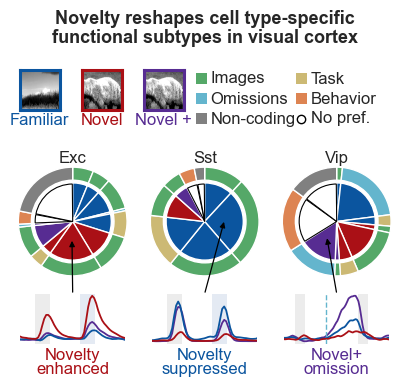

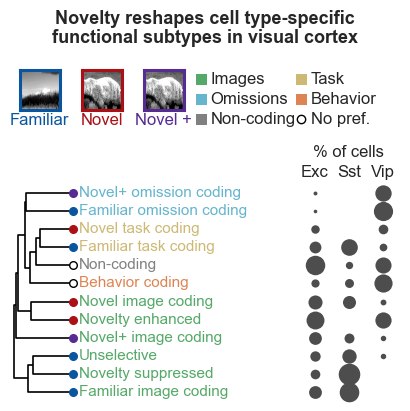

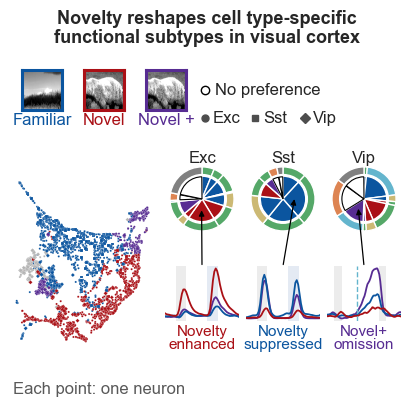

In [9]:
# ---- Graphical abstract v3: 4 x 4 in (Cell Press: 1200 x 1200 px at 300 dpi), two versions ----
# Shared header: title + key (one familiar / novel image, framed in the experience-level colours).
#   'pies'       : per-cell-type pies (outer ring = preferred feature, inner pie = preferred experience; one wedge per
#                  cluster) with example cluster traces below, arrows from each trace to its wedge.
#   'umap'       : UMAP coloured by each cluster's preferred experience level (marker = cell type) | per-cell-type
#                  pies (wedge = cluster, fill = preferred experience) with example cluster traces below.
#   'dendrogram' : Fig 5 dendrogram, cluster names coloured by preferred feature, leaf dots by preferred experience,
#                  and bubbles = % of each cell type's cells per cluster.
# Needs (from the cells above): cluster_meta, cluster_info, leaf_order, dendro_Z, dendro_labels, pie_fracs, pie_order,
# scatter_umap, features, feature_cols, exp_levels, exp_cols; for traces change_mdf / omission_mdf; for the key images
# familiar_templates / novel_templates.
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import ConnectionPatch, Rectangle, Wedge
from matplotlib.lines import Line2D
from matplotlib.colors import to_hex
from scipy.cluster.hierarchy import dendrogram

# ---------------- knobs ----------------
plt.rcParams['font.family'] = ['Arial', 'DejaVu Sans']
FIG_IN, DPI    = 4.0, 300
TITLE          = 'Novelty reshapes cell type-specific\nfunctional subtypes in visual cortex'
TITLE_FS, FS, SMALL_FS = 13, 12, 11          # Cell Press asks for >= 12 pt; SMALL_FS for cluster names (long / tight)
VERSIONS       = ['pies', 'dendrogram', 'umap']
RING_W, RING_GAP, SEP_LW = 0.24, 0.05, 1.0   # pie: outer feature ring width, white gap, wedge separators (radius = 1)
# cluster names (graphical_abstract_v2 CLUSTER_NAMES; cluster 5 prefers Novel +, so 'Novel+ image coding')
CLUSTER_NAMES  = {1: 'Non-coding', 2: 'Novelty enhanced', 3: 'Novel image coding', 4: 'Familiar image coding',
                  5: 'Novel+ image coding', 6: 'Novelty suppressed', 7: 'Unselective', 8: 'Familiar omission coding',
                  9: 'Novel+ omission coding', 10: 'Familiar task coding', 11: 'Novel task coding', 12: 'Behavior coding'}
NOPREF_COLOR   = '#b5b5b5'                   # no preferred experience (UMAP points); pies use white + outline
CT_SHORT       = {'Excitatory': 'Exc', 'Sst Inhibitory': 'Sst', 'Vip Inhibitory': 'Vip'}
MARKERS        = {'Excitatory': 'o', 'Sst Inhibitory': 's', 'Vip Inhibitory': 'D'}
# key images: template names (None = first in sorted order); crop window as in the original abstract
KEY_IMAGES     = {'Familiar': None, 'Novel': None}
KEY_CROP       = dict(x=(480, 1400), y=(220, 980))
# example traces, one per pie: cell type -> cluster (omission clusters are omission-aligned, others change-aligned)
TRACES         = {'Excitatory': 2, 'Sst Inhibitory': 6, 'Vip Inhibitory': 9}
TRACE_LW       = 1.3
SAVE           = True

ci = cluster_info
exp_c = dict(zip(exp_levels, [to_hex(c) for c in exp_cols]))


def _ok(col):
    return col is not None and not (isinstance(col, float) and np.isnan(col))


def _exp_color(cid, none=NOPREF_COLOR):
    c = ci.loc[cid, 'exp_color']
    return to_hex(c) if _ok(c) else none


def _feat_color(cid):
    return to_hex(ci.loc[cid, 'feature_color'])


def _fx(x_in):  return x_in / FIG_IN                 # inches -> figure fraction
def _fy(y_in):  return 1 - y_in / FIG_IN             # inches from the top -> figure fraction


def _key_image(level):
    tpl = familiar_templates if level == 'Familiar' else novel_templates
    name = KEY_IMAGES['Familiar' if level == 'Familiar' else 'Novel'] or np.sort(tpl.index)[0]
    im = tpl.loc[name]['unwarped'].copy(); im[np.isnan(im)] = 150
    return im[KEY_CROP['y'][0]:KEY_CROP['y'][1], KEY_CROP['x'][0]:KEY_CROP['x'][1]]


def draw_header(fig, key_x0, key_w, legend):
    """Title, then the key: familiar / novel / novel+ image (Novel + = the novel images on later days)."""
    fig.text(0.5, _fy(0.06), TITLE, ha='center', va='top', fontsize=TITLE_FS, fontweight='bold', linespacing=1.05)
    size, gap, top = 0.40, 0.22, 0.66                                   # thumbnail size / gap / top (in)
    for i, level in enumerate(exp_levels):
        x = key_x0 + i * (size + gap)
        a = fig.add_axes([_fx(x), _fy(top + size), _fx(size), size / FIG_IN])
        a.imshow(_key_image(level), cmap='gray', aspect='auto'); a.set_xticks([]); a.set_yticks([])
        for sp in a.spines.values():                                    # full frame (the VB style hides top/right)
            sp.set_visible(True); sp.set_edgecolor(exp_c[level]); sp.set_linewidth(2.2)
        fig.text(_fx(x + size / 2), _fy(top + size + 0.03), level, ha='center', va='top', fontsize=FS,
                 color=exp_c[level])
    legend(fig, key_x0 + 3 * size + 2 * gap + 0.12, top)


def legend_nopref(fig, x, top):
    fig.add_artist(Line2D([_fx(x + 0.07)], [_fy(top + 0.2)], marker='o', ms=6, mfc='white', mec='k', mew=1,
                          transform=fig.transFigure))
    fig.text(_fx(x + 0.17), _fy(top + 0.2), 'No preference', va='center', fontsize=FS)
    for i, ct in enumerate(['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']):
        xx = x + 0.07 + i * 0.5
        fig.add_artist(Line2D([_fx(xx)], [_fy(top + 0.48)], marker=MARKERS[ct], ms=5, color='0.3',
                              transform=fig.transFigure))
        fig.text(_fx(xx + 0.08), _fy(top + 0.48), CT_SHORT[ct], va='center', fontsize=FS)


def legend_features(fig, x, top):
    names = {'all-images': 'Images', 'omissions': 'Omissions', 'task': 'Task', 'behavioral': 'Behavior'}
    items = [(names[f], feature_cols[1 + i]) for i, f in enumerate(features)]
    items = items[:2] + [('Non-coding', feature_cols[0])] + items[2:]      # columns: images/omissions/non-coding | task/behavior
    for i, (lab, col) in enumerate(items):
        xx, yy = x + (i // 3) * 1.0, top + 0.08 + (i % 3) * 0.2
        fig.add_artist(Rectangle((_fx(xx), _fy(yy + 0.065)), _fx(0.11), 0.11 / FIG_IN, fc=col, ec='none',
                                 transform=fig.transFigure))
        fig.text(_fx(xx + 0.15), _fy(yy + 0.01), lab, va='center', fontsize=FS)
    fig.add_artist(Line2D([_fx(x + 1.055)], [_fy(top + 0.49)], marker='o', ms=6, mfc='white', mec='k', mew=1,
                          transform=fig.transFigure))
    fig.text(_fx(x + 1.15), _fy(top + 0.49), 'No pref.', va='center', fontsize=FS)


def _plot_trace(ax, cell_type, cid):
    """Mean response of one cluster's cells of one cell type, per experience level (as in Fig 5 / v2)."""
    omitted = ci.loc[cid, 'dominant_feature'] == 'omissions'
    mdf = omission_mdf if omitted else change_mdf
    csids = cluster_meta.index[(cluster_meta.cluster_id == cid) & (cluster_meta.cell_type == cell_type)]
    sub = mdf[mdf.cell_specimen_id.isin(csids)]
    ts = mdf['trace_timestamps'].values[0]
    for i in [2, 0, 1]:                                       # Novel + (back), Familiar, Novel (front)
        tr = sub[sub.experience_level == exp_levels[i]].mean_trace.values
        if len(tr):
            utils.plot_mean_trace(np.asarray(tr), ts, ylabel='', legend_label=None, color=exp_cols[i],
                                  interval_sec=1, plot_sem=False, linewidth=TRACE_LW,
                                  xlim_seconds=[-1, 1.5] if omitted else [-1, 0.75], ax=ax)
    utils.plot_flashes_on_trace(ax, ts, change=not omitted, omitted=omitted, alpha=0.15)
    ax.set_xlabel(''); ax.set_ylabel('')


def draw_pie(ax, cell_type):
    """One wedge per cluster in pie_order, clockwise from 12 (as graphical_abstract_v2): outer ring = preferred
    feature (gray = non-coding), white gap, inner pie = preferred experience (white + outline = no preference).
    Returns {cluster: (x, y) inside its inner wedge} for the trace arrows."""
    f = pie_fracs.loc[cell_type, pie_order]
    f = f[f > 0]
    r_in, theta, mids = 1 - RING_W - RING_GAP, 90.0, {}
    for c, frac in f.items():
        t1, t0 = theta, theta - 360 * frac
        ax.add_patch(Wedge((0, 0), 1, t0, t1, width=RING_W, fc=_feat_color(c), ec='white', lw=SEP_LW))
        if _ok(ci.loc[c, 'exp_color']):
            ax.add_patch(Wedge((0, 0), r_in, t0, t1, fc=to_hex(ci.loc[c, 'exp_color']), ec='white', lw=SEP_LW))
        else:
            ax.add_patch(Wedge((0, 0), r_in - 0.02, t0 + 0.6, t1 - 0.6, fc='white', ec='k', lw=0.8))
        a = np.deg2rad((t0 + t1) / 2)
        mids[c] = (0.5 * r_in * np.cos(a), 0.5 * r_in * np.sin(a))
        theta = t0
    ax.set_xlim(-1.03, 1.03); ax.set_ylim(-1.03, 1.03); ax.set_aspect('equal'); ax.axis('off')
    return mids


def _pie_with_trace(fig, ct, xc, d_pie, pie_top, trace_top, trace_w, trace_h, label_fs):
    pax = fig.add_axes([_fx(xc - d_pie / 2), _fy(pie_top + d_pie), _fx(d_pie), d_pie / FIG_IN])
    mids = draw_pie(pax, ct)
    pax.set_title(CT_SHORT[ct], fontsize=FS, pad=2)
    cid = TRACES[ct]
    tax = fig.add_axes([_fx(xc - trace_w / 2), _fy(trace_top + trace_h), _fx(trace_w), trace_h / FIG_IN])
    _plot_trace(tax, ct, cid)
    tax.set_xticks([]); tax.set_yticks([]); [sp.set_visible(False) for sp in tax.spines.values()]
    name = CLUSTER_NAMES[cid].replace(' coding', '').replace(' ', '\n', 1)
    fig.text(_fx(xc), _fy(trace_top + trace_h + 0.04), name, ha='center', va='top', fontsize=label_fs,
             color=_exp_color(cid, 'k'), linespacing=0.95)
    fig.add_artist(ConnectionPatch(xyA=(0.5, 1.0), coordsA=tax.transAxes, xyB=mids[cid], coordsB=pax.transData,
                                   arrowstyle='-|>', mutation_scale=8, lw=0.9, color='k', shrinkA=1, shrinkB=0,
                                   zorder=10))


def make_pies_version():
    fig = plt.figure(figsize=(FIG_IN, FIG_IN))
    draw_header(fig, key_x0=0.15, key_w=1.8, legend=legend_features)
    for ct, xc in zip(['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory'], [0.68, 2.0, 3.32]):
        _pie_with_trace(fig, ct, xc, d_pie=1.12, pie_top=1.62, trace_top=2.9, trace_w=1.05, trace_h=0.5, label_fs=FS)
    return fig


def make_umap_version():
    fig = plt.figure(figsize=(FIG_IN, FIG_IN))
    draw_header(fig, key_x0=0.15, key_w=1.8, legend=legend_nopref)
    # UMAP: left column
    top, bottom = 1.42, 3.74
    ax = fig.add_axes([_fx(0.03), _fy(bottom), _fx(1.45), (bottom - top) / FIG_IN])
    pal = {c: _exp_color(c) for c in ci.index}
    for ct in ['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory']:          # interneurons on top
        d = scatter_umap[scatter_umap.cell_type == ct]
        ax.scatter(d.x, d.y, s=2.2 if ct == 'Excitatory' else 4, marker=MARKERS[ct],
                   c=d.cluster_id.map(pal), linewidths=0.1, edgecolors='w', rasterized=True)
    ax.set_aspect('equal', adjustable='datalim'); ax.axis('off')
    fig.text(_fx(0.06), _fy(bottom + 0.04), 'Each point: one neuron', ha='left', va='top', fontsize=FS, color='0.35')
    # pies + traces: right column
    for ct, xc in zip(['Excitatory', 'Sst Inhibitory', 'Vip Inhibitory'], [1.95, 2.76, 3.57]):
        _pie_with_trace(fig, ct, xc, d_pie=0.66, pie_top=1.62, trace_top=2.62, trace_w=0.74, trace_h=0.55,
                        label_fs=SMALL_FS)
    return fig


def make_dendrogram_version():
    fig = plt.figure(figsize=(FIG_IN, FIG_IN))
    draw_header(fig, key_x0=0.15, key_w=1.8, legend=legend_features)
    top, bottom = 1.80, 3.97
    n = len(leaf_order)
    # dendrogram (left), leaves top -> bottom in leaf_order
    dax = fig.add_axes([_fx(0.06), _fy(bottom), _fx(0.62), (bottom - top) / FIG_IN])
    dendrogram(dendro_Z, labels=dendro_labels, ax=dax, orientation='left', link_color_func=lambda k: 'k',
               no_labels=True)
    for ln in dax.collections:
        ln.set_linewidth(1.2)
    ylim = (0, 10 * n); dax.set_ylim(ylim); dax.axis('off')
    leaves_bottom_up = leaf_order[::-1]
    yc = {c: 5 + 10 * j for j, c in enumerate(leaves_bottom_up)}
    for c, y in yc.items():
        col = ci.loc[c, 'exp_color']
        dax.plot(0, y, 'o', ms=5.5, mew=1, clip_on=False, zorder=4,
                 mfc=to_hex(col) if _ok(col) else 'white', mec=to_hex(col) if _ok(col) else 'k')
    # names (coloured by preferred feature) and bubbles share the dendrogram's y axis
    nax = fig.add_axes([_fx(0.74), _fy(bottom), _fx(3.22), (bottom - top) / FIG_IN], sharey=dax)
    nax.axis('off'); nax.set_xlim(0, 3.22)
    xb = {'Excitatory': 2.36, 'Sst Inhibitory': 2.70, 'Vip Inhibitory': 3.04}
    for c, y in yc.items():
        nax.text(0, y, CLUSTER_NAMES[c], va='center', fontsize=SMALL_FS, color=_feat_color(c))
        for ct, x in xb.items():
            p = pie_fracs.loc[ct, c]
            if p > 0:
                nax.scatter(x, y, s=p * 900, color='0.3', lw=0, clip_on=False)
    for ct, x in xb.items():
        nax.text(x, 10 * n + 2, CT_SHORT[ct], ha='center', va='bottom', fontsize=FS)
    nax.text(np.mean(list(xb.values())), 10 * n + 13, '% of cells', ha='center', va='bottom', fontsize=FS)
    return fig


figs = {}
for version in VERSIONS:
    fig = {'pies': make_pies_version, 'umap': make_umap_version, 'dendrogram': make_dendrogram_version}[version]()
    figs[version] = fig
    # check: all text inside the canvas, and font sizes
    fig.canvas.draw(); _r = fig.canvas.get_renderer()
    _out = [t.get_text()[:20] for t in fig.findobj(plt.Text) if t.get_text() and t.get_visible() and
            not (fig.bbox.contains(*t.get_window_extent(_r).p0) and fig.bbox.contains(*t.get_window_extent(_r).p1))]
    _sizes = sorted({t.get_fontsize() for t in fig.findobj(plt.Text) if t.get_text()})
    print(f'{version}: text outside canvas: {_out or "none"} | font sizes used: {_sizes}')
    if SAVE:
        for ext in ['tif', 'png', 'pdf']:
            kw = {'pil_kwargs': {'compression': 'tiff_lzw'}} if ext == 'tif' else {}
            fig.savefig(os.path.join(save_dir, f'graphical_abstract_v3_{version}.{ext}'), dpi=DPI, **kw)
